# Data Science Challenge - Dataset C: minimising a town's COVID vaccine and hospitalisation costs

## Task description
**Context.** A town will be infected by COVID with 100% probability. By local law everyone who wants a vaccine must get one. Vaccines are posted to people's homes and are ruined if not used, so we must decide **for each individual** whether to send a vaccine. If someone wants a vaccine and we do not send one, the town pays them the vaccine price instead (and, we assume, they stay unvaccinated).

**Costs.** Vaccine: $1,500. Hospitalisation for COVID: $41,000.

**Goal.** For every respondent in the test set, predict `covid_vaccine` (1 = send a vaccine, 0 = do not send) so that the **town's total expected cost** (vaccines + expected hospitalisations) is as low as possible.

**Data.** `dataset_C_training.csv` (4,756 respondents, 30 features + target `covid_vaccine`) and `dataset_C_testing.csv` (4,749 respondents, no target). Features cover covid opinions and behaviour, demographics, employment and health (see the data dictionary).

**Why accuracy is the wrong metric.** The two kinds of mistake cost different amounts:
- sending a vaccine to someone who refuses wastes **$1,500**
- not sending to someone who would accept loses the reduction in hospitalisation risk, **(p_unvacc - p_vacc) x $41,000**

**Approach.**
1. Explore the data (EDA).
2. Pre-process and compare options.
3. Model P(person accepts) with several calibrated classifiers, tuned and cross-validated.
4. Estimate hospitalisation risk (generative AI is allowed for this only) and derive a cost-optimal decision threshold per person.
5. Evaluate by dollar cost with cross-validation, test robustness to the risk assumptions, and submit the 5 best, ordered by cost.
6. Explain the models (XAI).

**Decision rule (derived).** Expected cost of sending = 1500 + 41000 x [q p_v + (1-q) p_u]. Expected cost of not sending = 1500 q + 41000 p_u (q = P(accept)).
Sending is cheaper when **q > 1500 / (1500 + 41000 x (p_u - p_v))**.

## 1. Setup

In [ ]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss
from sklearn.inspection import permutation_importance
warnings.filterwarnings("ignore")

VACCINE_COST, HOSP_COST = 1500, 41000
GROUP_NUMBER = 0                                  # <-- EDIT: your group number
TRAIN_PATH = "dataset_C_training.csv"
TEST_PATH = "dataset_C_testing.csv"
ID, TARGET = "respondent_id", "covid_vaccine"

## 2. Load data

In [ ]:
train, test = pd.read_csv(TRAIN_PATH), pd.read_csv(TEST_PATH)
print(train.shape, test.shape)
assert TARGET in train.columns and TARGET not in test.columns
y = train[TARGET].astype(int).values
X = train.drop(columns=[ID, TARGET])
X_test = test[X.columns]
print("Share accepting the vaccine:", y.mean().round(3))

(4756, 31) (4749, 30)
Share accepting the vaccine: 0.327


## 3. Exploratory data analysis
After each plot, **write your own observation** in a markdown cell (the rubric rewards interpretation, not plots).

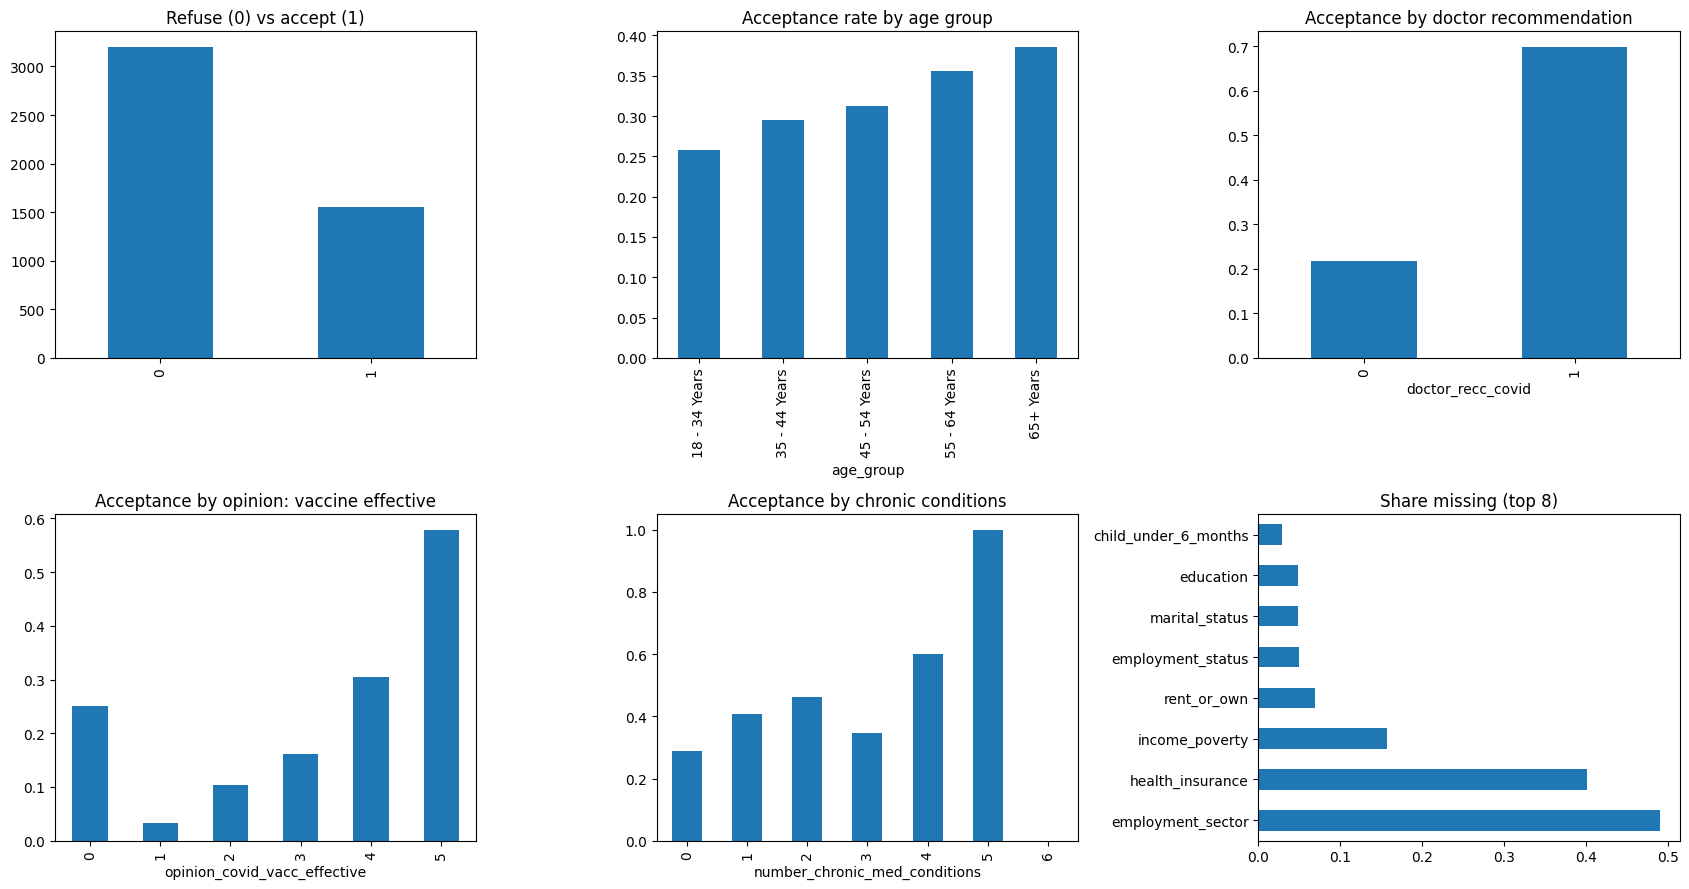

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
pd.Series(y).value_counts().sort_index().plot.bar(ax=ax[0,0], title="Refuse (0) vs accept (1)")
train.groupby("age_group")[TARGET].mean().plot.bar(ax=ax[0,1], title="Acceptance rate by age group")
train.groupby("doctor_recc_covid")[TARGET].mean().plot.bar(ax=ax[0,2], title="Acceptance by doctor recommendation")
train.groupby("opinion_covid_vacc_effective")[TARGET].mean().plot.bar(ax=ax[1,0], title="Acceptance by opinion: vaccine effective")
train.groupby("number_chronic_med_conditions")[TARGET].mean().plot.bar(ax=ax[1,1], title="Acceptance by chronic conditions")
train.isna().mean().sort_values(ascending=False).head(8).plot.barh(ax=ax[1,2], title="Share missing (top 8)")
plt.tight_layout(); plt.show()

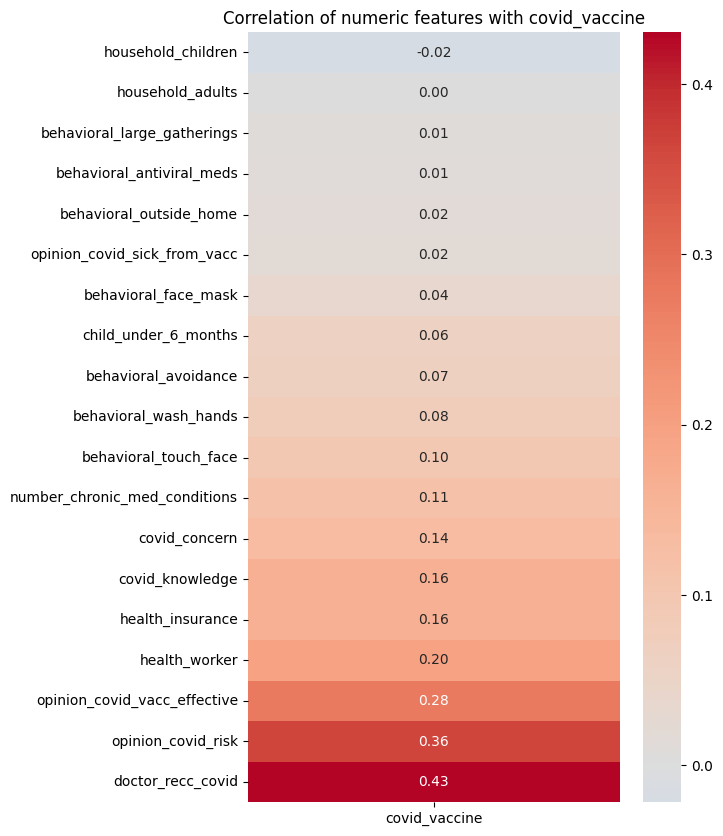

In [ ]:
corr = train.select_dtypes("number").drop(columns=[ID]).corr()[[TARGET]].drop(TARGET).sort_values(TARGET)
plt.figure(figsize=(6, 10)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation of numeric features with covid_vaccine"); plt.show()

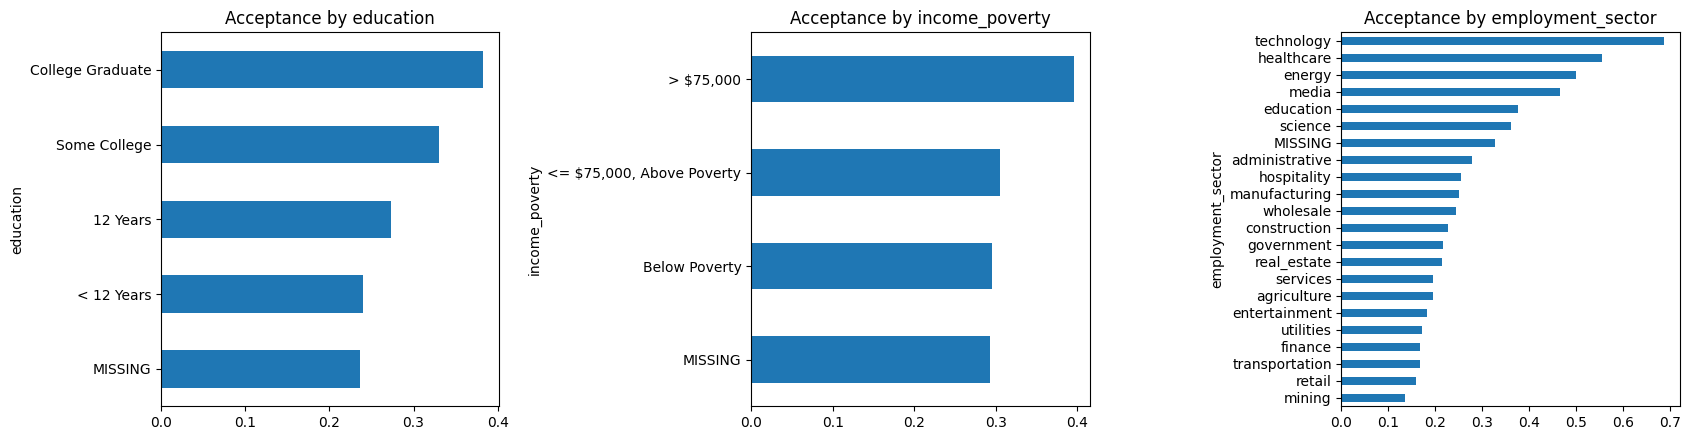

Train vs test feature balance (age_group share):
               train   test
age_group                  
65+ Years      0.254  0.268
55 - 64 Years  0.209  0.219
45 - 54 Years  0.199  0.199
18 - 34 Years  0.199  0.180
35 - 44 Years  0.139  0.134


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for a, col in zip(ax, ["education", "income_poverty", "employment_sector"]):
    train.fillna({col: "MISSING"}).groupby(col)[TARGET].mean().sort_values().plot.barh(ax=a, title=f"Acceptance by {col}")
plt.tight_layout(); plt.show()
print("Train vs test feature balance (age_group share):")
print(pd.concat([train.age_group.value_counts(normalize=True), test.age_group.value_counts(normalize=True)], axis=1, keys=["train", "test"]).round(3))

## 4. Hospitalisation risk (generative AI part)
We need p_unvacc and p_vacc for each person. **The values below are PLACEHOLDERS - replace them with your team's AI-consensus values**
(ask several AIs / several teammates, record prompts and answers, compare, use a central value and keep a low and a high version).

Structure: base risk by age group x (multiplier per chronic condition) and the vaccine reduces hospitalisation risk by VE.
`SCENARIOS` rescales the overall risk level for the robustness analysis.

In [ ]:
# ===== REPLACE WITH YOUR AI-CONSENSUS VALUES =====
AGE_RISK = [(35, 0.004), (45, 0.006), (55, 0.010), (65, 0.020), (999, 0.050)]  # (age < upper bound, P(hosp | unvaccinated))
CHRONIC_MULT = 1.5      # risk multiplier per chronic condition
MAX_CONDITIONS = 3      # conditions above this are rare in the data (see EDA) so the multiplier is capped
VE_HOSP = 0.60          # relative reduction in hospitalisation risk from vaccination
SCENARIOS = {"low": 0.5, "central": 1.0, "high": 2.0}
# =================================================

def hosp_probs(df, scale=1.0):
    """Return (p_unvaccinated, p_vaccinated) hospitalisation probabilities for each row of df."""
    ages = df["age_group"].astype(str).str.extract(r"(\d+)")[0].astype(float)
    ages = ages.fillna(ages.median()).values
    base = np.full(len(df), AGE_RISK[-1][1])
    for upper, risk in reversed(AGE_RISK):
        base = np.where(ages < upper, risk, base)
    n = df["number_chronic_med_conditions"].fillna(0).clip(0, MAX_CONDITIONS).values
    p_u = np.clip(base * CHRONIC_MULT ** n * scale, 0, 1)
    return p_u, p_u * (1 - VE_HOSP)

p_u, p_v = hosp_probs(X)
print("Mean p_unvacc:", p_u.mean().round(4), "| mean delta-p:", (p_u - p_v).mean().round(4))

Mean p_unvacc: 0.0261 | mean delta-p: 0.0156


## 5. Cost function and decision rule
- Vaccine cost is paid if we send a vaccine **or** the person wanted one (town reimburses).
- Hospital cost uses p_vacc only if the person is actually vaccinated (we sent AND they accept), otherwise p_unvacc.

In [ ]:
def total_cost(accepts, send, p_u, p_v):
    accepts, send = np.asarray(accepts).astype(bool), np.asarray(send).astype(bool)
    vaccine_cost = VACCINE_COST * (send | accepts).sum()
    hosp_cost = HOSP_COST * np.where(send & accepts, p_v, p_u).sum()
    return vaccine_cost + hosp_cost

def decide(q, p_u, p_v):
    """Send a vaccine when q > 1500 / (1500 + 41000 * delta_p)."""
    return (q > VACCINE_COST / (VACCINE_COST + HOSP_COST * (p_u - p_v))).astype(int)

# sanity check of the derivation: brute-force the cheapest decision for one person with q = 0.5
q0, pu0, pv0 = 0.5, 0.03, 0.012
exp_send = VACCINE_COST + HOSP_COST * (q0 * pv0 + (1 - q0) * pu0)
exp_not = VACCINE_COST * q0 + HOSP_COST * pu0
print("expected cost send:", exp_send, "| not send:", exp_not, "| rule says send:", bool(decide(np.array([q0]), pu0, pv0)[0]))

expected cost send: 2361.0 | not send: 1980.0 | rule says send: False


## 6. Pre-processing pipeline and cross-validation harness
`build_pipe` lets us compare pre-processing choices (imputation strategy, treating missing values as their own category + missing-indicators, with/without demographic features).
`cv_cost` returns **cost per person on each validation fold**, so we can see the random variation, not just a mean.

In [ ]:
def build_pipe(cols, kind, clf, impute="median", missing_as_category=False):
    num = X[cols].select_dtypes("number").columns.tolist()
    cat = [c for c in cols if c not in num]
    num_imp = SimpleImputer(strategy=impute, add_indicator=missing_as_category)
    cat_imp = (SimpleImputer(strategy="constant", fill_value="MISSING") if missing_as_category
               else SimpleImputer(strategy="most_frequent"))
    if kind == "linear":
        n = Pipeline([("imp", num_imp), ("sc", StandardScaler())])
        c = Pipeline([("imp", cat_imp), ("oh", OneHotEncoder(handle_unknown="ignore"))])
    else:
        n = num_imp
        c = Pipeline([("imp", cat_imp), ("oe", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))])
    return Pipeline([("pre", ColumnTransformer([("num", n, num), ("cat", c, cat)])), ("clf", clf)])

def cv_cost(model, cols, scale=1.0, dec_scale=None, n_splits=5, seed=42):
    # cost per person per fold; decisions use risk scale dec_scale (default = scale), scoring uses scale
    dec_scale = scale if dec_scale is None else dec_scale
    costs = []
    for tr, va in StratifiedKFold(n_splits, shuffle=True, random_state=seed).split(X, y):
        m = clone(model).fit(X.iloc[tr][cols], y[tr])
        q = m.predict_proba(X.iloc[va][cols])[:, 1]
        pu, pv = hosp_probs(X.iloc[va], scale)            # "true" risk used for scoring
        pu_d, pv_d = hosp_probs(X.iloc[va], dec_scale)    # risk assumed when deciding
        costs.append(total_cost(y[va], decide(q, pu_d, pv_d), pu, pv) / len(va))
    return np.array(costs)

def report(name, costs):
    print(f"{name:42s} cost/person = {costs.mean():8.1f} +/- {costs.std():5.1f}")

all_cols = X.columns.tolist()
no_demog = [c for c in all_cols if c not in ("race", "sex")]

# reference strategies (central scenario), evaluated on the full training data
pu_c, pv_c = hosp_probs(X)
report("send to everyone (reference)", np.array([total_cost(y, np.ones(len(y)), pu_c, pv_c) / len(y)]))
report("send to no one (reference)", np.array([total_cost(y, np.zeros(len(y)), pu_c, pv_c) / len(y)]))

send to everyone (reference)               cost/person =   2327.4 +/-   0.0
send to no one (reference)                 cost/person =   1559.5 +/-   0.0


## 7. Pre-processing comparison (logistic regression as the probe model)

In [ ]:
lr = LogisticRegression(max_iter=2000, C=0.5)
prep_results = {
 "median impute, mode for categories": cv_cost(build_pipe(all_cols, "linear", lr), all_cols),
 "mean impute, mode for categories":   cv_cost(build_pipe(all_cols, "linear", lr, impute="mean"), all_cols),
 "missing as its own category + indicators": cv_cost(build_pipe(all_cols, "linear", lr, missing_as_category=True), all_cols),
 "without race and sex":               cv_cost(build_pipe(no_demog, "linear", lr), no_demog),
}
for k, v in prep_results.items():
    report(k, v)

median impute, mode for categories         cost/person =   1472.2 +/-  17.9
mean impute, mode for categories           cost/person =   1469.3 +/-  18.0
missing as its own category + indicators   cost/person =   1462.2 +/-  13.8
without race and sex                       cost/person =   1473.6 +/-  17.9


**Interpretation (write your own):** compare the differences between options with the fold-to-fold spread (the +/-). If a difference is smaller than the spread, it is not meaningful.

## 8. Models, calibration and tuning
Probabilities must be well calibrated because the decision threshold depends directly on q. Tree models are wrapped in isotonic calibration.

In [ ]:
rf = CalibratedClassifierCV(RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=0), method="isotonic", cv=3)
hgb = CalibratedClassifierCV(HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, random_state=0), method="isotonic", cv=3)
model_results = {
  "logistic regression": prep_results["median impute, mode for categories"],
  "random forest (calibrated)": cv_cost(build_pipe(all_cols, "tree", rf), all_cols),
  "hist gradient boosting (calibrated)": cv_cost(build_pipe(all_cols, "tree", hgb), all_cols),
}
for k, v in model_results.items():
    report(k, v)

logistic regression                        cost/person =   1472.2 +/-  17.9
random forest (calibrated)                 cost/person =   1472.7 +/-  19.5
hist gradient boosting (calibrated)        cost/person =   1478.9 +/-  20.0


best params: {'clf__min_samples_leaf': 50, 'clf__max_iter': 100, 'clf__max_depth': 3, 'clf__learning_rate': 0.05, 'clf__l2_regularization': 0.1} | best CV log-loss: 0.4643
hist gradient boosting (tuned)             cost/person =   1471.6 +/-  17.2


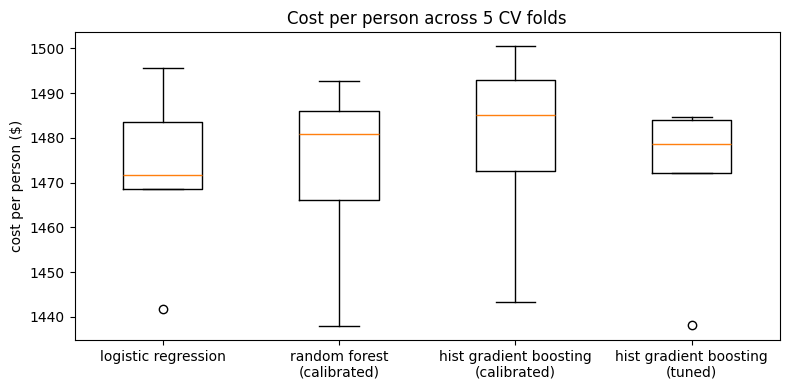

In [ ]:
# Hyper-parameter tuning of the boosting model on log-loss (good probabilities -> good thresholds)
search = RandomizedSearchCV(
    build_pipe(all_cols, "tree", HistGradientBoostingClassifier(random_state=0)),
    {"clf__learning_rate": [0.02, 0.05, 0.1], "clf__max_depth": [3, 5, None],
     "clf__max_iter": [100, 200, 400], "clf__l2_regularization": [0, 0.1, 1.0],
     "clf__min_samples_leaf": [20, 50, 100]},
    n_iter=15, scoring="neg_log_loss", cv=3, random_state=0, n_jobs=-1).fit(X, y)
print("best params:", search.best_params_, "| best CV log-loss:", round(-search.best_score_, 4))
tuned = {k.replace("clf__", ""): v for k, v in search.best_params_.items()}
hgb_tuned = CalibratedClassifierCV(HistGradientBoostingClassifier(random_state=0, **tuned), method="isotonic", cv=3)
model_results["hist gradient boosting (tuned)"] = cv_cost(build_pipe(all_cols, "tree", hgb_tuned), all_cols)
report("hist gradient boosting (tuned)", model_results["hist gradient boosting (tuned)"])

plt.figure(figsize=(8, 4))
plt.boxplot(list(model_results.values()))
plt.xticks(range(1, len(model_results) + 1), [k.replace(" (", "\n(") for k in model_results]); plt.ylabel("cost per person ($)")
plt.title("Cost per person across 5 CV folds"); plt.tight_layout(); plt.show()

**Probability quality.** Besides cost, check discrimination and calibration of the out-of-fold probabilities.

tuned HGB: AUC=0.831  log-loss=0.469  brier=0.148


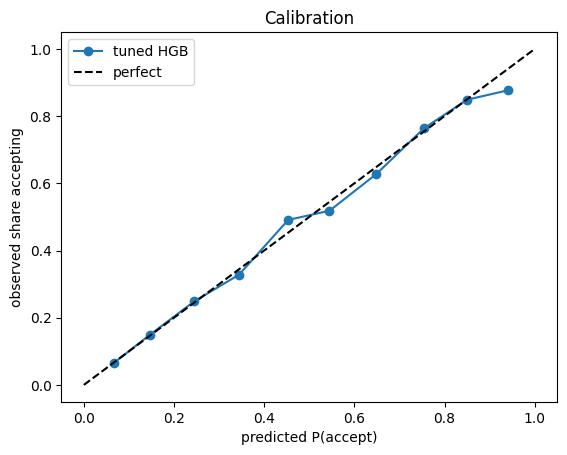

In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.calibration import calibration_curve
oof = cross_val_predict(build_pipe(all_cols, "tree", hgb_tuned), X, y, cv=StratifiedKFold(5, shuffle=True, random_state=42), method="predict_proba")[:, 1]
print(f"tuned HGB: AUC={roc_auc_score(y, oof):.3f}  log-loss={log_loss(y, oof):.3f}  brier={brier_score_loss(y, oof):.3f}")
frac, mean_pred = calibration_curve(y, oof, n_bins=10)
plt.plot(mean_pred, frac, "o-", label="tuned HGB"); plt.plot([0, 1], [0, 1], "k--", label="perfect")
plt.xlabel("predicted P(accept)"); plt.ylabel("observed share accepting"); plt.legend(); plt.title("Calibration"); plt.show()

## 9. Robustness to the risk assumptions
We do not know the true risks, so we make decisions under each scenario and evaluate under every scenario.

In [ ]:
# reuse out-of-fold probabilities, decide with one scenario, score with another
table = pd.DataFrame(index=list(SCENARIOS), columns=list(SCENARIOS), dtype=float)
for dec_s, dec_scale in SCENARIOS.items():
    pu_d, pv_d = hosp_probs(X, dec_scale)
    send = decide(oof, pu_d, pv_d)
    for ev_s, ev_scale in SCENARIOS.items():
        pu_e, pv_e = hosp_probs(X, ev_scale)
        table.loc[dec_s, ev_s] = total_cost(y, send, pu_e, pv_e) / len(y)
table.index.name, table.columns.name = "decided under", "true risk"
print(table.round(1))

true risk         low  central    high
decided under                         
low             994.0   1476.4  2441.3
central        1001.8   1471.6  2411.1
high           1028.4   1482.8  2391.7


## 10. The five submissions
Five different pipelines, forming a progression (baseline -> pre-processing -> different model family -> tuned model -> alternative risk assumption).
They are **ordered by cross-validated cost per person under the central risk scenario** (lowest cost = order 1).

In [ ]:
plan = {
 "A logistic regression (baseline)":      (build_pipe(all_cols, "linear", LogisticRegression(max_iter=2000, C=0.5)), all_cols, 1.0),
 "B logistic regression, missing-aware":  (build_pipe(all_cols, "linear", LogisticRegression(max_iter=2000, C=0.5), missing_as_category=True), all_cols, 1.0),
 "C random forest (calibrated)":          (build_pipe(all_cols, "tree", rf), all_cols, 1.0),
 "D hist gradient boosting (tuned)":      (build_pipe(all_cols, "tree", hgb_tuned), all_cols, 1.0),
 "E tuned HGB, decisions under HIGH risk": (build_pipe(all_cols, "tree", hgb_tuned), all_cols, SCENARIOS["high"]),
}
scores = {n: cv_cost(m, cols, scale=1.0, dec_scale=d) for n, (m, cols, d) in plan.items()}
ranking = sorted(scores, key=lambda n: scores[n].mean())
for n in ranking:
    report(n, scores[n])

B logistic regression, missing-aware       cost/person =   1462.2 +/-  13.8
D hist gradient boosting (tuned)           cost/person =   1471.6 +/-  17.2
A logistic regression (baseline)           cost/person =   1472.2 +/-  17.9
C random forest (calibrated)               cost/person =   1472.7 +/-  19.5
E tuned HGB, decisions under HIGH risk     cost/person =   1482.8 +/-  16.3


In [ ]:
os.makedirs("submissions", exist_ok=True)
for order, n in enumerate(ranking, start=1):
    model, cols, dec_scale = plan[n]
    model.fit(X[cols], y)
    q_test = model.predict_proba(X_test[cols])[:, 1]
    pu_t, pv_t = hosp_probs(X_test, dec_scale)
    send = decide(q_test, pu_t, pv_t)
    out = pd.DataFrame({ID: test[ID], TARGET: send})
    path = f"submissions/challenge_submission_group_{GROUP_NUMBER}_order_{order}.csv"
    out.to_csv(path, index=False)
    print(path, "<-", n, "| vaccines sent:", int(send.sum()), "of", len(send))

ex = pd.read_csv("dataset_C_example_submission.csv") if os.path.exists("dataset_C_example_submission.csv") else None
if ex is not None:
    chk = pd.read_csv(f"submissions/challenge_submission_group_{GROUP_NUMBER}_order_1.csv")
    print("columns match example:", list(chk.columns) == list(ex.columns), "| ids match:", set(chk[ID]) == set(ex[ID]))

submissions/challenge_submission_group_0_order_1.csv <- B logistic regression, missing-aware | vaccines sent: 792 of 4749
submissions/challenge_submission_group_0_order_2.csv <- D hist gradient boosting (tuned) | vaccines sent: 684 of 4749
submissions/challenge_submission_group_0_order_3.csv <- A logistic regression (baseline) | vaccines sent: 692 of 4749
submissions/challenge_submission_group_0_order_4.csv <- C random forest (calibrated) | vaccines sent: 671 of 4749
submissions/challenge_submission_group_0_order_5.csv <- E tuned HGB, decisions under HIGH risk | vaccines sent: 1046 of 4749


## 11. Explainable AI (can be completed after the hackathon)
Permutation importance and partial dependence for the tuned boosting model on a held-out split, plus SHAP when the library is available.

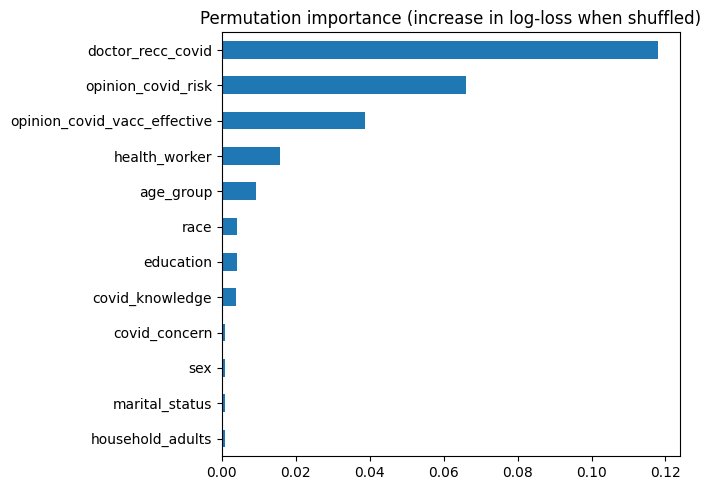

In [ ]:
Xtr, Xva, ytr, yva = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
xai_model = build_pipe(all_cols, "tree", hgb_tuned).fit(Xtr, ytr)
pi = permutation_importance(xai_model, Xva, yva, scoring="neg_log_loss", n_repeats=10, random_state=0, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=all_cols).sort_values().tail(12)
imp.plot.barh(figsize=(7, 5), title="Permutation importance (increase in log-loss when shuffled)"); plt.tight_layout(); plt.show()

PermutationExplainer explainer: 501it [01:43,  4.37it/s]


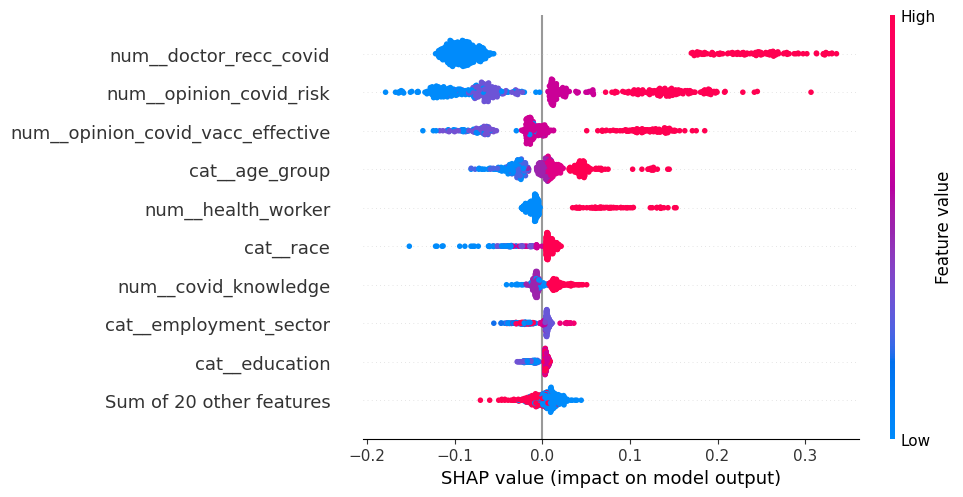

In [ ]:
try:
    import shap
    pre = xai_model.named_steps["pre"]
    names = pre.get_feature_names_out()
    Xs = pd.DataFrame(pre.transform(Xva), columns=names).sample(500, random_state=0)
    gbm = HistGradientBoostingClassifier(random_state=0, **tuned).fit(pre.transform(Xtr), ytr)
    exp = shap.Explainer(gbm.predict_proba, Xs)(Xs)
    shap.plots.beeswarm(exp[:, :, 1])
except ImportError:
    print("shap not installed: run `pip install shap` in Colab and re-run this cell")